# Hands-On P06 — Perceptron dari Nol hingga Siap Dipasang di Mikrokontroler
**Mata kuliah:** Edge Intelligence and Computing (CCE60306) · **Pertemuan 6**

Tujuan: (1) mengimplementasikan perceptron dengan NumPy, (2) memvisualisasikan batas keputusannya, (3) membuktikan keterbatasannya pada XOR,
(4) membandingkan dengan scikit-learn dan Keras, serta (5) menerapkannya pada dataset HO-05 (diam vs bergerak) dan mengekspor bobotnya ke C.

Berkas yang dibutuhkan: `dataset_siap_latih.npz` (keluaran HO-05, disediakan di folder yang sama).

Nama  : Rezky Auliasarie

NIM   : 245150300111014

Kelas : B

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron as SkPerceptron

## 1. Data: Iris setosa vs non-setosa (2 fitur: panjang dan lebar petal)

In [ ]:
iris = load_iris()
X = iris.data[:, [2, 3]]                 # panjang & lebar petal (cm)
y = (iris.target == 0).astype(int)       # 1 = setosa, 0 = bukan
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)
sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
print(Xtr.shape, Xte.shape, np.bincount(ytr))

(120, 2) (30, 2) [80 40]


## 2. Perceptron dengan NumPy
Model: z = w·x + b, ŷ = step(z). Aturan belajar Rosenblatt: w ← w + η (y − ŷ) x, b ← b + η (y − ŷ).

In [ ]:
class PerceptronNP:
    def __init__(self, n, eta=0.1, seed=0):
        rng = np.random.default_rng(seed)
        self.w = rng.normal(0, 0.1, n); self.b = 0.0; self.eta = eta
    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)
    def fit(self, X, y, epochs=20, verbose=True):
        self.riwayat = []
        for ep in range(epochs):
            salah = 0
            for xi, yi in zip(X, y):
                e = yi - int(xi @ self.w + self.b >= 0)
                if e != 0:
                    self.w += self.eta * e * xi; self.b += self.eta * e; salah += 1
            self.riwayat.append(salah)
            if verbose: print(f"epoch {ep+1:2d}: {salah} kesalahan")
            if salah == 0: break
        return self

p = PerceptronNP(2).fit(Xtr, ytr)
print("w =", p.w.round(3), "b =", round(p.b, 3), "| akurasi uji =", (p.predict(Xte) == yte).mean())

epoch  1: 1 kesalahan
epoch  2: 0 kesalahan
w = [-0.062 -0.051] b = -0.1 | akurasi uji = 1.0


## 3. Batas keputusan w·x + b = 0

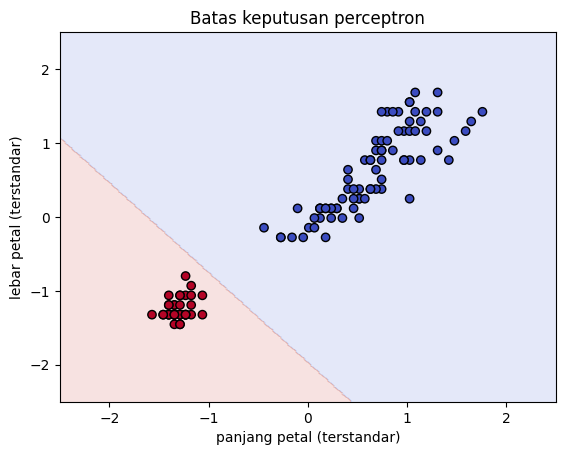

In [ ]:
xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 300), np.linspace(-2.5, 2.5, 300))
zz = p.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, zz, alpha=0.15, cmap="coolwarm")
plt.scatter(*Xtr.T, c=ytr, cmap="coolwarm", edgecolor="k")
plt.xlabel("panjang petal (terstandar)"); plt.ylabel("lebar petal (terstandar)"); plt.title("Batas keputusan perceptron"); plt.show()

## 4. Satu langkah pembaruan secara manual (samakan dengan contoh hitung di modul)

In [ ]:
w, b, eta = np.array([0.2, -0.4]), 0.0, 0.5
x, y_benar = np.array([1.0, 0.25]), 0
z = w @ x + b; y_hat = int(z >= 0)
print(f"z = {z:.2f} -> ŷ = {y_hat}, galat = {y_benar - y_hat}")
w = w + eta * (y_benar - y_hat) * x; b = b + eta * (y_benar - y_hat)
print("w baru =", w, "b baru =", b)

z = 0.10 -> ŷ = 1, galat = -1
w baru = [-0.3   -0.525] b baru = -0.5


## 5. Pembanding: scikit-learn

In [ ]:
sk = SkPerceptron(eta0=0.1, random_state=0).fit(Xtr, ytr)
print("akurasi uji sklearn:", sk.score(Xte, yte), "| w =", sk.coef_.round(3), "b =", sk.intercept_.round(3))

akurasi uji sklearn: 1.0 | w = [[-0.125 -0.129]] b = [-0.1]


## 6. Gerbang logika: AND dan OR bisa, XOR tidak

In [ ]:
Xg = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
for nama, yg in {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}.items():
    pg = PerceptronNP(2, eta=0.1).fit(Xg, np.array(yg), epochs=100, verbose=False)
    print(f"{nama}: prediksi {pg.predict(Xg)} | target {yg} | kesalahan epoch terakhir = {pg.riwayat[-1]}")

AND: prediksi [0 0 0 1] | target [0, 0, 0, 1] | kesalahan epoch terakhir = 0
OR: prediksi [0 1 1 1] | target [0, 1, 1, 1] | kesalahan epoch terakhir = 0
XOR: prediksi [1 0 0 0] | target [0, 1, 1, 0] | kesalahan epoch terakhir = 4


## 7. Fungsi aktivasi

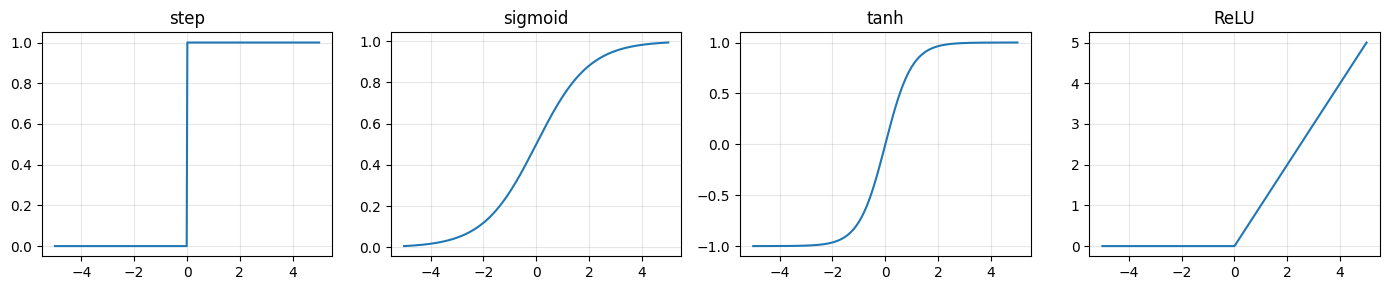

In [ ]:
z = np.linspace(-5, 5, 400)
akt = {"step": (z >= 0).astype(float), "sigmoid": 1 / (1 + np.exp(-z)), "tanh": np.tanh(z), "ReLU": np.maximum(0, z)}
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for a, (n, v) in zip(axs, akt.items()): a.plot(z, v); a.set_title(n); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8. (Colab) Neuron sigmoid dengan Keras
Satu `Dense(1, activation="sigmoid")` = perceptron dengan aktivasi sigmoid yang dilatih dengan *binary cross-entropy*.

akurasi uji Keras: 1.0


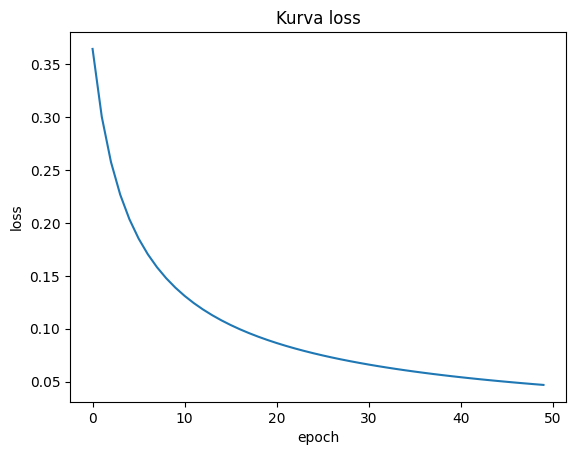

In [ ]:
import tensorflow as tf
tf.random.set_seed(0)
m = tf.keras.Sequential([tf.keras.Input(shape=(2,)), tf.keras.layers.Dense(1, activation="sigmoid")])
m.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.1), loss="binary_crossentropy", metrics=["accuracy"])
h = m.fit(Xtr, ytr, epochs=50, batch_size=16, verbose=0)
print("akurasi uji Keras:", m.evaluate(Xte, yte, verbose=0)[1])
plt.plot(h.history["loss"]); plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Kurva loss"); plt.show()

## 9. Terapkan pada dataset HO-05: diam vs bergerak

In [ ]:
d = np.load("dataset_siap_latih.npz")
Xa, ya = d["X_train"], (d["y_train"] > 0).astype(int)     # 0 = diam, 1 = jalan/lari
Xu, yu = d["X_test"], (d["y_test"] > 0).astype(int)
pa = PerceptronNP(Xa.shape[1], eta=0.05).fit(Xa, ya, epochs=30, verbose=False)
print("jumlah fitur:", Xa.shape[1], "| epoch:", len(pa.riwayat), "| akurasi uji:", (pa.predict(Xu) == yu).mean())

jumlah fitur: 22 | epoch: 2 | akurasi uji: 0.9903846153846154


## 10. Ekspor bobot ke C (siap dipakai di ESP32)

In [ ]:
def ke_c(w, b, mean, scale):
    f = lambda a: ", ".join(f"{v:.6f}f" for v in a)
    return (f"const int N = {len(w)};\n"
            f"const float W[N] = {{{f(w)}}};\nconst float B = {b:.6f}f;\n"
            f"const float MU[N] = {{{f(mean)}}};\nconst float SD[N] = {{{f(scale)}}};\n"
            "int prediksi(const float *x) {            // x = fitur mentah\n"
            "  float z = B;\n"
            "  for (int i = 0; i < N; i++) z += W[i] * (x[i] - MU[i]) / SD[i];\n"
            "  return z >= 0.0f;                     // 1 = bergerak\n}\n")
kode = ke_c(pa.w, pa.b, d["scaler_mean"], d["scaler_scale"])
open("perceptron_diam_bergerak.h", "w").write(kode); print(kode[:400], "...")
print("Memori bobot float32:", (len(pa.w) + 1) * 4, "byte")

const int N = 22;
const float W[N] = {-0.042707f, 0.102742f, -0.090971f, 0.074593f, 0.062143f, -0.014951f, 0.223221f, -0.029171f, -0.015251f, -0.033163f, -0.015367f, 0.033220f, -0.188985f, 0.060795f, -0.079742f, -0.001150f, -0.004793f, 0.102344f, 0.103264f, 0.173163f, -0.062853f, 0.186646f};
const float B = 0.150000f;
const float MU[N] = {-0.001318f, 0.307580f, -0.664916f, 0.660856f, 0.308027f, 0. ...
Memori bobot float32: 92 byte


## Latihan
1. Ubah laju belajar η menjadi 0,001 dan 1. Bagaimana jumlah epoch sampai konvergen?
2. Ulangi bagian 9 untuk **jalan vs lari** saja. Apakah perceptron masih memadai? Mengapa?
3. Hitung jumlah operasi perkalian-penjumlahan (MAC) fungsi `prediksi()` untuk 22 fitur.

1. Pengerjaan Nomor 1 (Pengaruh Laju Belajar (eta) terhadap Konvergensi)
:


In [ ]:
# Nomor 1: Pengaruh Laju Belajar (eta) terhadap Konvergensi
import numpy as np

d = np.load("dataset_siap_latih.npz")
Xa, ya = d["X_train"], (d["y_train"] > 0).astype(int)
Xu, yu = d["X_test"], (d["y_test"] > 0).astype(int)

for eta_val in [0.001, 1]:
    pa = PerceptronNP(Xa.shape[1], eta=eta_val, seed=0).fit(Xa, ya, epochs=50, verbose=False)

    epoch_konvergen = next((i + 1 for i, e in enumerate(pa.riwayat) if e == 0), "Belum konvergen")
    acc = (pa.predict(Xu) == yu).mean()

    print(f"Laju Belajar (eta) = {eta_val:<5} | Epoch Konvergen: {str(epoch_konvergen):<15} | Akurasi Uji: {acc:.4f}")

Laju Belajar (eta) = 0.001 | Epoch Konvergen: 12              | Akurasi Uji: 0.9904
Laju Belajar (eta) = 1     | Epoch Konvergen: 2               | Akurasi Uji: 0.9904


Penjelasan:

Pada latihan ini diuji pengaruh nilai laju belajar terhadap proses konvergensi Perceptron dengan menggunakan eta = 0,001 dan eta = 1. Hasil program menunjukkan bahwa pada η = 0,001, model membutuhkan 12 epoch untuk konvergen dengan akurasi uji 0,9904 atau 99,04%, sedangkan pada η = 1, model hanya membutuhkan 2 epoch dengan akurasi uji yang sama, yaitu 99,04%. Hal ini menunjukkan bahwa laju belajar yang lebih besar membuat perubahan bobot pada setiap pembaruan menjadi lebih besar sehingga model mencapai kondisi konvergen lebih cepat, sedangkan laju belajar yang sangat kecil membutuhkan lebih banyak epoch.

2. Pengerjaan Nomor 2 (Klasifikasi Jalan vs Lari Menggunakan Perceptron)



In [ ]:
# Nomor 2: Klasifikasi Jalan vs Lari Menggunakan Perceptron
import numpy as np

d = np.load("dataset_siap_latih.npz")

mask_tr = d["y_train"] > 0
mask_te = d["y_test"] > 0

X_jl_tr = d["X_train"][mask_tr]
y_jl_tr = (d["y_train"][mask_tr] == 2).astype(int)

X_jl_te = d["X_test"][mask_te]
y_jl_te = (d["y_test"][mask_te] == 2).astype(int)

p_jl = PerceptronNP(X_jl_tr.shape[1], eta=0.05, seed=0).fit(X_jl_tr, y_jl_tr, epochs=30, verbose=False)
acc_jl = (p_jl.predict(X_jl_te) == y_jl_te).mean()

print(f"Jumlah fitur         : {X_jl_tr.shape[1]}")
print(f"Epoch                : {len(p_jl.riwayat)}")
print(f"Kesalahan epoch akhir: {p_jl.riwayat[-1]}")
print(f"Akurasi Uji         : {acc_jl:.4f}")

Jumlah fitur         : 22
Epoch                : 4
Kesalahan epoch akhir: 0
Akurasi Uji         : 0.6610


Penjelasan:

Pada latihan ini klasifikasi dibatasi hanya pada aktivitas jalan dan lari dengan tetap menggunakan 22 fitur dan Perceptron yang sama seperti bagian 9. Hasil program menunjukkan model mencapai konvergensi pada epoch ke-4 dengan 0 kesalahan pada epoch terakhir, tetapi akurasi pengujiannya hanya 0,6610 atau 66,10%. Hasil tersebut menunjukkan bahwa Perceptron belum cukup memadai untuk membedakan jalan dan lari dengan baik, karena meskipun model berhasil mempelajari data training hingga tidak terdapat kesalahan, kemampuan generalisasinya pada data testing masih rendah. Kondisi ini menunjukkan bahwa pola antara jalan dan lari kemungkinan lebih sulit dipisahkan menggunakan batas keputusan linear yang digunakan oleh Perceptron.

3. Pengerjaan Nomor 3 (Perhitungan Operasi MAC dan Operasi Aritmatika C)

In [ ]:
# Nomor 3: Perhitungan Operasi MAC dan Operasi Aritmatika C
N = 22  # Jumlah fitur

mac_count = N

print(f"Jumlah fitur (N)   : {N}")
print(f"Jumlah Operasi MAC : {mac_count} MAC")

Jumlah fitur (N)   : 22
Jumlah Operasi MAC : 22 MAC


Penjelasan:

Pada latihan ini jumlah operasi Multiply-Accumulate (MAC) dihitung berdasarkan jumlah fitur yang digunakan oleh fungsi prediksi(). Karena data memiliki 22 fitur, setiap fitur membutuhkan satu operasi perkalian antara nilai fitur dan bobotnya yang kemudian diakumulasikan ke hasil perhitungan. Program menetapkan N = 22 dan menghasilkan output 22 MAC, sehingga setiap satu kali proses prediksi membutuhkan 22 operasi perkalian-penjumlahan. Perhitungan bias dilakukan secara terpisah sehingga tidak dihitung sebagai MAC.

